# Random and structured directions

In [1]:
import torch

import numpy as np

from eszd import SSZD
from eszd.directions import SphericalDirections, HouseholderQRDirections, \
                            GaussianDirections, HouseholderReflection,\
                            DCTDirections, RandomCoords, DirectionMatrix,\
                            ButterflyDirections
import matplotlib.pyplot as plt

from math import sqrt

In [2]:
def target(x, z = None):
    return x.square().mean(dim=1)

In [3]:

d = 100
l = d//5
alpha = lambda t: l/d * 15.0# * 1/sqrt(t)
h = lambda t : 1e-7 #/ sqrt(t)
gaussian_P = SphericalDirections(d=d, l=l, dtype=torch.float64, device='cpu')
structured_P = ButterflyDirections(d=d, l=l, dtype=torch.float64, device='cpu')

In [4]:
opt_st = SSZD(structured_P, alpha=alpha, h=h)
opt_gd = SSZD(gaussian_P, alpha=alpha, h=h)

In [5]:
T = 500
x0 = torch.full((1, d), 1e4)

ris_st = opt_st.optimize(target, x0, T=T)
ris_gd = opt_gd.optimize(target, x0, T=T)


In [6]:
trace_st, it_st = [], []
trace_gd, it_gd = [], []

for i in range(len(ris_st[2])):
    for _ in range(l):
        trace_st.append(ris_st[2][i])
        trace_gd.append(ris_gd[2][i])
                



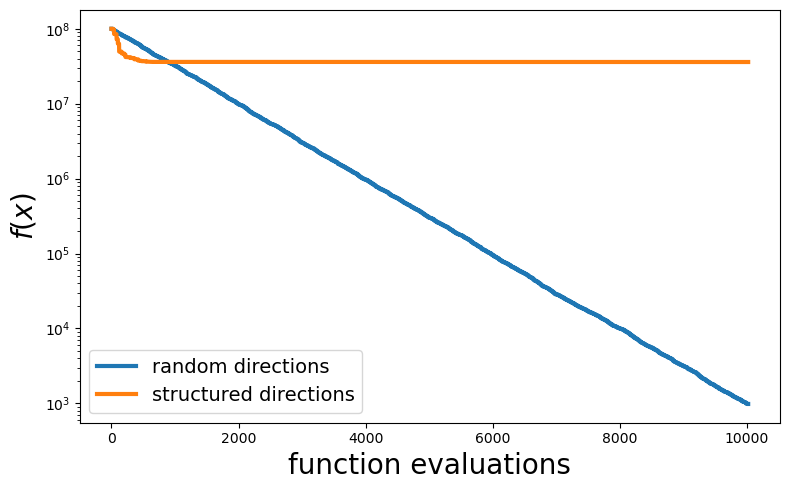

In [7]:
fig, ax1 = plt.subplots(1, 1, figsize=(8, 5))
ax1.plot(range(len(trace_gd)), trace_gd,'-', lw=3, label="random directions")
ax1.plot(range(len(trace_st)), trace_st,'-', lw=3, label="structured directions")
ax1.set_yscale("log")
ax1.set_xlabel("function evaluations", fontsize=20)
ax1.set_ylabel("$f(x)$", fontsize=20)
ax1.legend(fontsize=14)
#ax2.plot(range(len(ris_gd[1])), np.cumsum(ris_gd[1]),'-', lw=3, label="random directions")
#ax2.plot(range(len(ris_st[1])), np.cumsum(ris_st[1]),'-', lw=3, label="structured directions")
#ax2.set_xlabel("iteration",fontsize=20)
#ax2.set_ylabel("$s$",fontsize=20)
#ax2.legend()
plt.tight_layout()
plt.savefig("structured_vs_random.pdf", bbox_inches='tight')



## Random vs Structured: Computational Cost

In [2]:
import time 


dims = [1, 10, 100, 1000, 10000]
reps = 5

def compute_time(P):
    it_time = time.time()
    P()
    it_time = time.time() - it_time
    return it_time

ctimes = {
    'gaussian' : [[] for _ in range(len(dims))],
    'coords' : [[] for _ in range(len(dims))],
    'spherical' : [[] for _ in range(len(dims))],
    'householder' : [[] for _ in range(len(dims))],
    'dct' : [[] for _ in range(len(dims))],
    'butterfly' : [[] for _ in range(len(dims))],
    'qr' : [[] for _ in range(len(dims))]
}

device = 'cuda'
dtype = torch.float32

for i, d in enumerate(dims):
    C = RandomCoords(d=d,l=d,dtype=dtype, device =device)
    S = SphericalDirections(d=d, l=d, dtype=dtype, device =device)
    G = GaussianDirections(d = d, l = d,dtype=dtype, device =device)
    H = HouseholderReflection(d = d, l = d,dtype=dtype, device =device)
    QR = HouseholderQRDirections(d = d, l = d, dtype=dtype, device=device)
    BTT = ButterflyDirections(d = d, l = d, dtype=dtype, device = device)
    DCT = DCTDirections(d = d, l= d, dtype=dtype, device=device)
    C()
    S()
    G()
    H()
    DCT()
    BTT()
    QR()

    for r in range(reps):
        
        ctimes['gaussian'][i].append(compute_time(G))
        ctimes['spherical'][i].append(compute_time(S))
        ctimes['coords'][i].append(compute_time(C))
        ctimes['householder'][i].append(compute_time(H))
        ctimes['dct'][i].append(compute_time(DCT))
        ctimes['butterfly'][i].append(compute_time(BTT))
        ctimes['qr'][i].append(compute_time(QR))
        



In [3]:
import numpy as np
ctimes['gaussian'] = np.mean(ctimes['gaussian'],1)
ctimes['spherical'] = np.mean(ctimes['spherical'],1)
ctimes['coords'] = np.mean(ctimes['coords'],1)
ctimes['householder'] = np.mean(ctimes['householder'],1)
ctimes['dct'] = np.mean(ctimes['dct'], 1)
ctimes['butterfly'] = np.mean(ctimes['butterfly'], 1)
ctimes['qr'] = np.mean(ctimes['qr'],1)

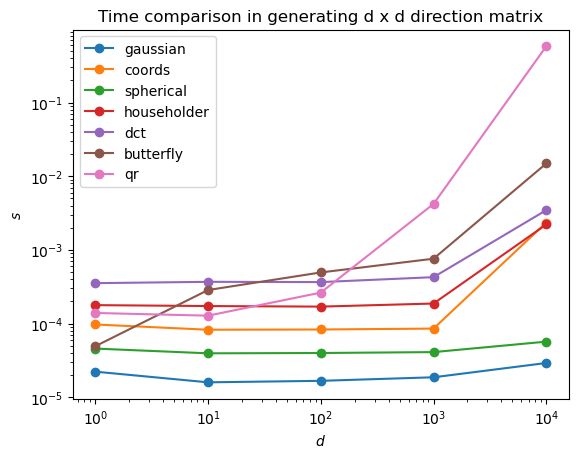

In [4]:


fig, ax = plt.subplots()

ax.set_title("Time comparison in generating d x d direction matrix")
for (k, v) in ctimes.items():
    ax.plot(dims, v, 'o-', label=k)
ax.set_yscale("log")
ax.set_xscale("log")
ax.set_xlabel("$d$")
ax.set_ylabel("$s$")
ax.legend()
fig.savefig("./time_comparison_dxd_{}.pdf".format(device), bbox_inches='tight')


In [23]:
from torch_dct import dct

device = 'cpu'
#P = HouseholderReflection(d=5, l=3)

d = 7
l = 3
nrm_const = sqrt(d/l)
P = ButterflyDirections(d=d, l=l)

A = P()

A = dct(A, norm='ortho')

print(A)

print(A.T @ A)


tensor([[-0.7455,  0.0026,  0.7674],
        [ 1.1731, -0.0236,  0.9708],
        [ 0.6316,  0.1656, -0.8887],
        [ 0.0494, -1.5183, -0.1107],
        [ 0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000]])
tensor([[ 2.3333e+00, -6.5374e-08,  1.8895e-08],
        [-6.5374e-08,  2.3333e+00, -2.4338e-08],
        [ 1.8895e-08, -2.4338e-08,  2.3333e+00]])


# ESZD & SimAnnealing

In [43]:
from torch.linalg import householder_product

A = torch.eye(4, 2)
tau = torch.randn((2))

H = householder_product(A, tau)



print(H)
print(H @ H.T)

tensor([[1.6705, 0.0000],
        [0.0000, 2.3140],
        [0.0000, 0.0000],
        [0.0000, 0.0000]])
tensor([[2.7906, 0.0000, 0.0000, 0.0000],
        [0.0000, 5.3547, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000]])
